# №4 зертханалық жұмыс
## Жіктеу есептерін шешу және k-NN, Decision Tree, SVM және Random Forest алгоритмдерін салыстыру.

Мақсат: алдын ала берілген жіктеуіштерді бірдей бөліністерде салыстыру, шекаралар мен нақты қателерді зерттеу. Байланысты материалдар: 4-тарау, 4.8–4.9-бөлімдер; `lab04.py`.

1-тәжірибе: make_moons арқылы 600 синтетикалық нүкте, noise 0.2. 2-тәжірибе: кіріктірілген нақты Digits. Барлық бастапқы күй — 2026. Test баптау үшін қолданылмайды. Кескіндер мен CSV `lab04_artifacts` ішіне сақталады; орта орнатылғаннан кейін сыртқы деректерді жүктеу қажет емес.

### 1–3-қадамдар. Орта және деректер
Бір Moons нүктесінде екі координата мен бинарлық белгі бар. Бір Digits кескінінде 64 пиксельдік белгі және 0–9 класс белгісі бар. Әр тәжірибе деректері стратификациямен 80/20 бір рет бөлінеді; бұл — барлық модельге ортақ бөлініс.

Таза ядрода бәрін жоғарыдан төменге орындаңыз. Сақталған шығыс әдістер топтарының әмбебап дәлдігіне емес, көрсетілген хаттамаға қатысты.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ROOT = Path.cwd() / "lab04_artifacts"
FIGURES = ROOT / "figures"
DATASETS = ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 4–6-қадамдар. Бекітілген модельдер
Dummy жиі класты болжайды. k-NN: 7 көрші; SVM: C=1, RBF, gamma=scale. Екеуі де StandardScaler қамтиды. Ағаш: max_depth=5. Орман: 200 ағаш, min_samples_leaf=2, max_features=sqrt, n_jobs=1, random_state=2026.

SVC ықтималдық калибрлеуін сұрамай, класс белгілері үшін қолданылады. sklearn 1.9 нұсқасында айқын probability параметрі ескірген; мұнда ол берілмейді. decision_function да, класс белгілері де ықтималдық ретінде ұсынылмайды.

In [2]:
def make_models():
    return {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "kNN": Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=7))]),
        "DecisionTree": DecisionTreeClassifier(max_depth=5, random_state=2026),
        "SVM": Pipeline([("scale", StandardScaler()),
                         ("model", SVC(C=1, kernel="rbf", gamma="scale"))]),
        "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                max_features="sqrt", n_jobs=1, random_state=2026)}

def fixed_comparison(X, y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=2026)
    labels = np.unique(y)
    models = make_models()
    rows, matrices = [], {}
    for name, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        rows.append({"model": name, "train_accuracy": accuracy_score(ytr, model.predict(Xtr)),
                     "test_accuracy": accuracy_score(yte, pred),
                     "F1macro": f1_score(yte, pred, average="macro"),
                     "correct": int(np.sum(pred==np.asarray(yte)))})
        matrices[name] = confusion_matrix(yte, pred, labels=labels).tolist()
    print(pd.DataFrame(rows).to_string(index=False))
    result = {"rows": len(X), "features": X.shape[1], "labels": labels.tolist(),
              "train_size": len(ytr), "test_size": len(yte), "seed": 2026,
              "class_counts": pd.Series(y).value_counts().sort_index().tolist(),
              "test_class_counts": pd.Series(yte).value_counts().sort_index().tolist(),
              "metrics": rows, "confusion_matrices": matrices,
              "split_disjoint": set(Xtr.index).isdisjoint(Xte.index),
              "scaler_samples_seen": {name: int(models[name].named_steps["scale"].n_samples_seen_)
                                       for name in ["kNN", "SVM"]}}
    return result, models, (Xtr, Xte, ytr, yte)



### 7-қадам. Синтетикалық доғалар және шекаралар
480 нүкте оқытылады, 120 нүкте тексеріледі. Суреттегі аймақтар сол конвейерлер арқылы есептеледі. Тест нүктесінің түсі шын класты, айқыш қатені білдіреді. Жергілікті, шектік, тегіс және ансамбльдік шекаралардың қалай ерекшеленетінін қараңыз.

       model  train_accuracy  test_accuracy  F1macro  correct
       Dummy        0.500000       0.500000 0.333333       60
         kNN        0.970833       0.966667 0.966657      116
DecisionTree        0.972917       0.925000 0.924953      111
         SVM        0.941667       0.933333 0.933315      112
RandomForest        0.985417       0.950000 0.949986      114


Матрицалар {'Dummy': [[60, 0], [60, 0]], 'kNN': [[59, 1], [3, 57]], 'DecisionTree': [[57, 3], [6, 54]], 'SVM': [[57, 3], [5, 55]], 'RandomForest': [[58, 2], [4, 56]]}


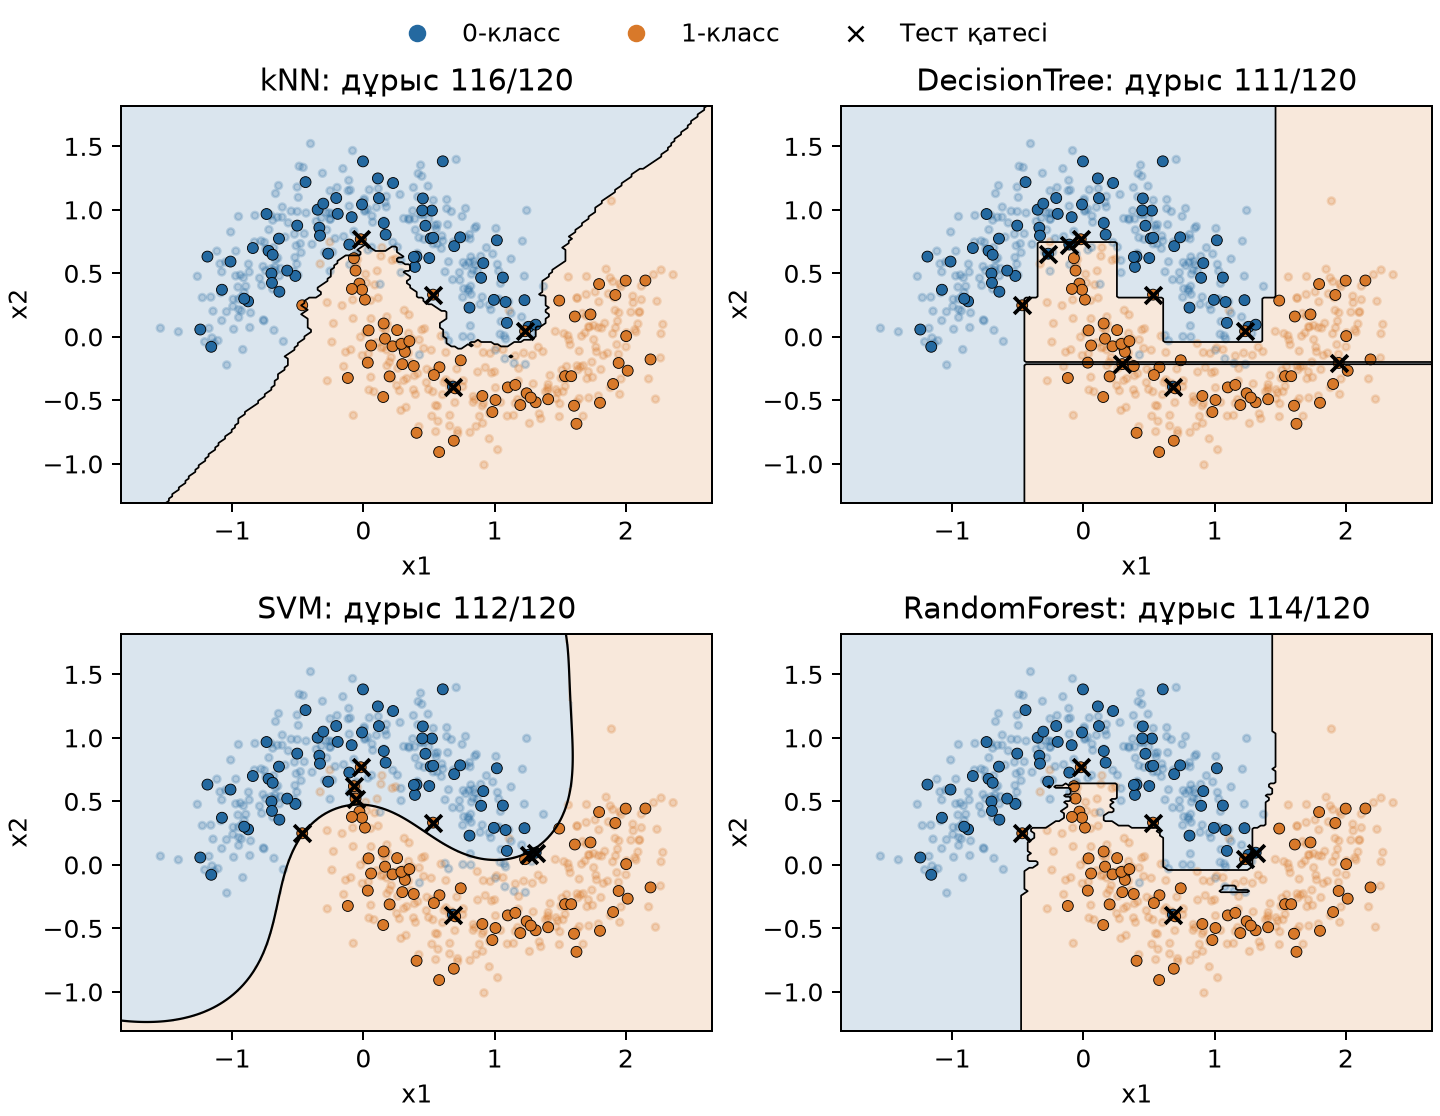

In [3]:
def moons_experiment():
    raw, target = make_moons(n_samples=600, noise=.2, random_state=2026)
    X, y = pd.DataFrame(raw, columns=["x1", "x2"]), pd.Series(target)
    result, models, parts = fixed_comparison(X, y)
    Xtr, Xte, ytr, yte = parts
    xx, yy = np.meshgrid(np.linspace(X.x1.min()-.3, X.x1.max()+.3, 180),
                         np.linspace(X.x2.min()-.3, X.x2.max()+.3, 180))
    grid = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})
    cmap = ListedColormap(["#2469A0", "#D8792A"])
    fig, axs = plt.subplots(2, 2, figsize=(8, 6.2), layout="constrained")
    for ax, name in zip(axs.ravel(), ["kNN", "DecisionTree", "SVM", "RandomForest"]):
        pred = models[name].predict(Xte)
        regions = models[name].predict(grid).reshape(xx.shape)
        ax.contourf(xx, yy, regions, levels=[-.5,.5,1.5], cmap=cmap, alpha=.17)
        if name == "SVM":
            score = models[name].decision_function(grid).reshape(xx.shape)
            ax.contour(xx, yy, score, levels=[0], colors="black", linewidths=.9)
        else:
            ax.contour(xx, yy, regions, levels=[.5], colors="black", linewidths=.7)
        ax.scatter(Xtr.x1, Xtr.x2, c=ytr, cmap=cmap, s=8, alpha=.22)
        ax.scatter(Xte.x1, Xte.x2, c=yte, cmap=cmap, s=19, edgecolor="black", linewidth=.35)
        wrong = pred!=yte.to_numpy()
        ax.scatter(Xte.loc[wrong,"x1"], Xte.loc[wrong,"x2"], marker="x", color="black", s=45)
        ax.set(title=f"{name}: дұрыс {int((~wrong).sum())}/{len(yte)}", xlabel="x1", ylabel="x2")
    handles = [Line2D([],[],marker="o",linestyle="",color="#2469A0",label="0-класс"),
               Line2D([],[],marker="o",linestyle="",color="#D8792A",label="1-класс"),
               Line2D([],[],marker="x",linestyle="",color="black",label="Тест қатесі")]
    fig.legend(handles=handles, loc="outside upper center", ncol=3, frameon=False)
    fig.savefig(FIGURES / "ch04_05_moons.png", dpi=180)
    plt.close(fig)
    X.assign(target=y).to_csv(DATASETS / "synthetic_moons.csv", index=False)
    result.update({"synthetic": True, "generator": "make_moons", "noise": .2,
                   "svm_n_support": models["SVM"].named_steps["model"].n_support_.tolist()})
    return result


moons_result = moons_experiment()
print("Матрицалар", moons_result["confusion_matrices"])
display(Image(filename=str(FIGURES / "ch04_05_moons.png")))


Тексерілген тәжірибеде k-NN 116/120, ағаш 111/120, SVM 112/120, орман 114/120 таниды. Бұл — нақты баптауларды салыстыру. k-NN [[59,1],[3,57]] матрицасы 116/120 Accuracy және 59/61 мен 57/59 орташа мәні ретінде F1-macro береді.

**Сіздің жауабыңыз.** Бір шекара бөлігін, бір қатені және Accuracy мен F1-macro айырмасын түсіндіріңіз. Тестті көргеннен кейін параметрлерді өзгертпеңіз.

_Өз түсіндірмеңізді жазыңыз._

### Digits: шығу тегі және тексеру аясы
Дереккөз: Alpaydin, E. & Kaynak, C. (1998), Optical Recognition of Handwritten Digits, UCI, [DOI 10.24432/C50P49](https://doi.org/10.24432/C50P49), CC BY 4.0. sklearn кіріктірілген көшірмесі бастапқы тест бөлігін қамтиды: 8×8 өлшемді 1797 кескін, 0–16 аралығындағы 64 белгі. Толық UCI жиынында 5620 жол бар. Көшірме ішіндегі жаңа 1437/360 бөлінісі бастапқы UCI benchmark тәжірибесін қайталамайды және жаңа қолжазба авторларына тасымалдауды дәлелдемейді.

Атрибуция экспортталған CSV жанындағы `Digits_Attribution.txt` ішінде сақталады.

In [4]:
digits_data = load_digits(as_frame=True)
print("Өлшемі:", digits_data.data.shape)
print("Жиіліктері:", digits_data.target.value_counts().sort_index().to_dict())
print("Жетіспейтін мәндер:", int(digits_data.frame.isna().sum().sum()))
print("Кескіндер:", digits_data.images.shape)
assert np.array_equal(digits_data.data.iloc[0].to_numpy().reshape(8,8), digits_data.images[0])
display(digits_data.frame.head())


Өлшемі: (1797, 64)
Жиіліктері: {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}
Жетіспейтін мәндер: 0
Кескіндер: (1797, 8, 8)


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


### 8-қадам. Цифрлар, матрица және қате кескіндер
Бес ереже алдын ала берілген сол параметрлер жиынын қайталайды. Егжей-тегжейлі диагностика үшін SVM алдын ала таңдалған. Кескіндер ортақ жарықтық ауқымымен бастапқы пиксельдерден қалпына келтіріледі; қарағаннан кейін модель параметрлері өзгертілмейді.

       model  train_accuracy  test_accuracy  F1macro  correct
       Dummy        0.101601       0.102778 0.018640       37
         kNN        0.980515       0.986111 0.985715      355
DecisionTree        0.711900       0.683333 0.666614      246
         SVM        0.997216       0.994444 0.994398      358
RandomForest        1.000000       0.969444 0.968742      349
SVM: Digits матрицасы
 [[36  0  0  0  0  0  0  0  0  0]
 [ 0 37  0  0  0  0  0  0  0  0]
 [ 0  0 34  0  1  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 36  0  0  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  1  0  0  0  0  0  0 34  0]
 [ 0  0  0  0  0  0  0  0  0 36]]
SVM алғашқы қателері: [{'row_id': 1273, 'true_class': 2, 'predicted_class': 4}, {'row_id': 1553, 'true_class': 8, 'predicted_class': 1}]


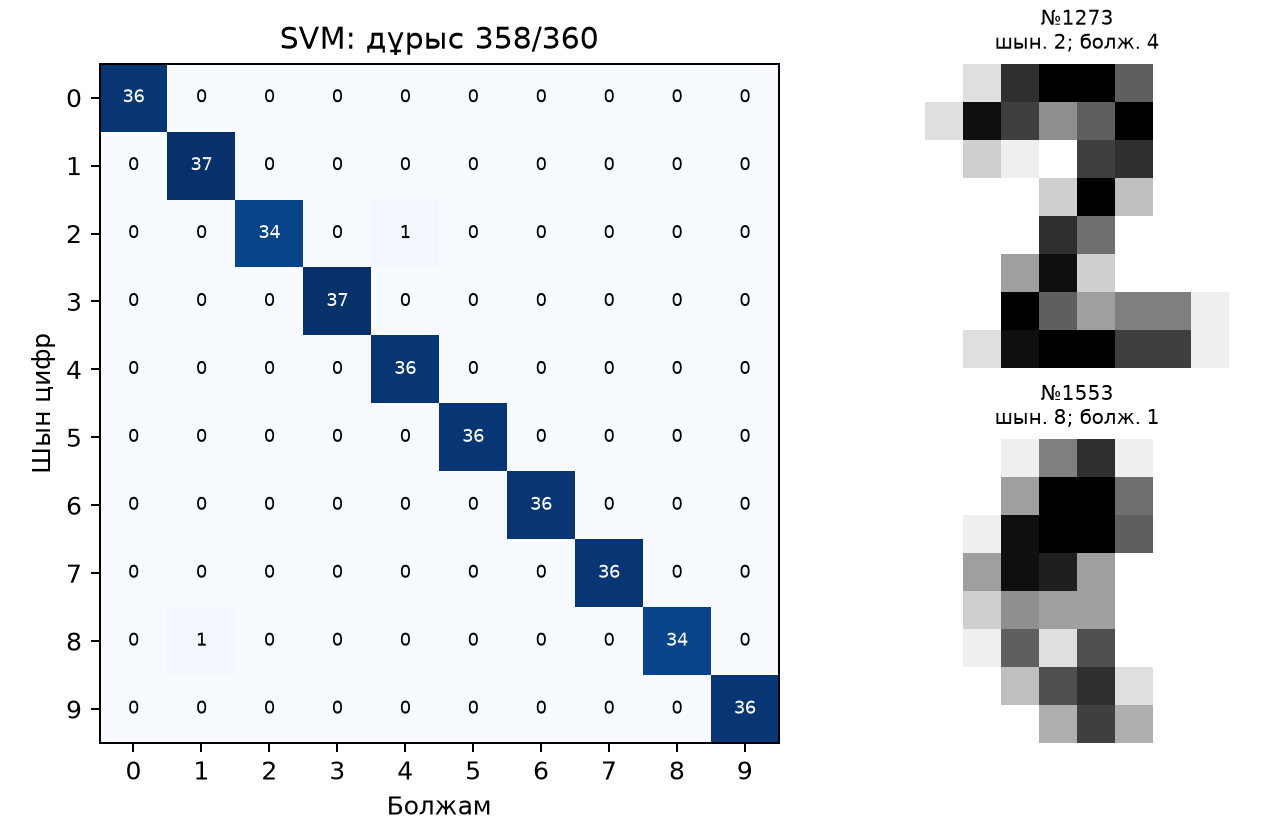

In [5]:
def digits_experiment():
    data = load_digits(as_frame=True)
    X, y = data.data, data.target
    result, models, parts = fixed_comparison(X, y)
    Xtr, Xte, ytr, yte = parts
    pred = models["SVM"].predict(Xte)
    wrong_positions = np.flatnonzero(pred!=yte.to_numpy())
    examples = [{"row_id": int(Xte.index[pos]), "true_class": int(yte.iloc[pos]),
                 "predicted_class": int(pred[pos])} for pos in wrong_positions[:6]]
    matrix = np.array(result["confusion_matrices"]["SVM"])
    print("SVM: Digits матрицасы\n", matrix)
    print("SVM алғашқы қателері:", examples)
    gallery_columns = max(1, int(np.ceil(len(examples)/2)))
    fig = plt.figure(figsize=(6.5+.6*gallery_columns, 4.6), layout="constrained")
    gs = fig.add_gridspec(2, 2+gallery_columns, width_ratios=[1, 1]+[.9]*gallery_columns)
    ax = fig.add_subplot(gs[:, :2])
    ax.imshow(matrix, cmap="Blues", vmin=0)
    ax.set(xticks=range(10), yticks=range(10), xlabel="Болжам", ylabel="Шын цифр",
           title=f"SVM: дұрыс {len(yte)-len(wrong_positions)}/{len(yte)}")
    for i in range(10):
        for j in range(10):
            ax.text(j,i,str(matrix[i,j]),ha="center",va="center",fontsize=7,
                    color="white" if matrix[i,j]>matrix.max()/2 else "black")
    for k in range(2*gallery_columns):
        ax = fig.add_subplot(gs[k//gallery_columns, k%gallery_columns+2])
        if k<len(examples):
            example = examples[k]
            ax.imshow(data.images[example["row_id"]], cmap="gray_r", vmin=0, vmax=16,
                      interpolation="nearest")
            ax.set_title(f"№{example['row_id']}\nшын. {example['true_class']}; болж. {example['predicted_class']}", fontsize=8)
        ax.set_axis_off()
    fig.savefig(FIGURES / "ch04_06_digits.png", dpi=180)
    plt.close(fig)
    data.frame.to_csv(DATASETS / "digits_sklearn.csv", index=False)
    attribution = ("Alpaydin, E. & Kaynak, C. (1998). Optical Recognition of Handwritten Digits [Dataset]. UCI.\n"
                   "DOI: https://doi.org/10.24432/C50P49\n"
                   "Source: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits\n"
                   "License: CC BY 4.0 https://creativecommons.org/licenses/by/4.0/\n"
                   "Export: sklearn.datasets.load_digits, copy of original UCI test subset, 1797 rows; full UCI dataset has 5620 rows.\n"
                   "Feature names follow scikit-learn; labels 0-9 unchanged; images reconstructed from the 64 features.\n"
                   "The educational 1437/360 split is new and does not reproduce the original UCI train/test benchmark.\n"
                   "Metadata checked 2026-11-04.\n")
    (DATASETS / "Digits_Attribution.txt").write_text(attribution, encoding="utf-8")
    result.update({"synthetic": False, "dataset": "Digits built-in copy of original UCI test subset",
                   "pixel_range": [float(X.to_numpy().min()), float(X.to_numpy().max())],
                   "svm_errors": len(wrong_positions), "svm_error_examples": examples,
                   "svm_n_support": models["SVM"].named_steps["model"].n_support_.tolist()})
    return result


digits_result = digits_experiment()
display(Image(filename=str(FIGURES / "ch04_06_digits.png")))


Тексерілген іске қосуда SVM 358/360 дұрыс таниды: 1273-жол (2→4), 1553-жол (8→1). k-NN 355, ағаш 246, орман 349 дұрыс жауап береді. SVM матрицасында екінің Recall мәні 34/35, төрттің Precision мәні 36/37.

**Сіздің жауабыңыз.** Диагональдан тыс бір ұяшықты түсіндіріп, кескін бойынша тексерілетін жорамал ұсыныңыз. Қарап шығу қолайсыз объектіні өшіруге неге рұқсат бермейді? Модельдер реті Moons жиынынан неге өзгеше?

_Өз түсіндірмеңізді жазыңыз._

### Сандық өзін-өзі тексеру
Хаттама құрамы, жолдардың қиылыспауы, scaler оқыту объектілерінің саны, матрицалар қосындылары және диагональдың Accuracy мәніне сәйкестігі тексеріледі. Бұл шарттар зерттеу қорытындысын бағалауды алмастырмайды.

In [6]:
assert moons_result["synthetic"] and not digits_result["synthetic"]
assert (moons_result["train_size"], moons_result["test_size"]) == (480,120)
assert (digits_result["train_size"], digits_result["test_size"]) == (1437,360)
for result, classes in [(moons_result,2), (digits_result,10)]:
    assert result["split_disjoint"]
    assert len(result["labels"]) == classes and len(result["metrics"]) == 5
    assert all(n == result["train_size"] for n in result["scaler_samples_seen"].values())
    for row in result["metrics"]:
        matrix = np.asarray(result["confusion_matrices"][row["model"]])
        assert matrix.shape == (classes,classes)
        assert matrix.sum() == result["test_size"]
        assert np.trace(matrix) == row["correct"]
        assert np.isclose(row["test_accuracy"], np.trace(matrix)/matrix.sum())
print("Бөліністерді, статистикаларды және матрицаларды өзіндік тексеру өтті.")


Бөліністерді, статистикаларды және матрицаларды өзіндік тексеру өтті.


### 9-қадам. Жеке нұсқалар
Баптауларды таңдау үшін train ішінен ішкі валидация бөліңіз. Базалық кестелерді сақтап, жоспарланған барлық нәтижені хабарлаңыз.

1. k=3 және k=7.
2. Ағаш тереңдігі 3 және 5.
3. RBF-SVM: C=0.3 және C=1.
4. Орман: max_features=sqrt және 1.0, басқа баптаулар бұрынғыдай.
5. Масштабтаумен және масштабтаусыз k-NN/SVM.
6. Таңдалған цифр жұбының ішкі тексерудегі шатастыру бағыттары: соларға бейімдемей, екі қате және бір дұрыс мысал.

**Сіздің нұсқаңыз, жорамалыңыз, хаттамаңыз және қорытындыңыз.**

_Өз түсіндірмелеріңіз бен кодыңызды қосыңыз._

### 10-қадам. Есеп және қорғау
Қойылымдар, дереккөздер, параметрлер, split, екі кесте, матрицалар, шекаралар, қате кескіндер, метриканы қолмен есептеу, нұсқалар, таза іске қосу және Digits атрибуциясы.

Жергілікті рубрика: қойылым мен дереккөздер 15%; split және ағып кетуден қорғау 20%; бес ереже 20%; метрикалар 15%; визуализация мен қателер 20%; қайталанушылық 10%. Барлығы толықтықтың 100%-ы; ресми ұпайлар силлабуспен және оқытушымен анықталады.

Бақылау сұрақтары: ортақ тест; scaler статистикалары; тақ k және көпкластық теңдіктер; тереңдік; SVM баптаулары; decision score және ықтималдық; орманның бірлік train score мәні; екінің Recall мәні; кіріктірілген көшірме мен толық UCI; модель таңдауға арналған деректер.

Әдістемелік негіз — Оспан Ә.Ғ. авторлық 4-дәрісі мен 4-ЗЖ. Бастапқы дереккөздер: [UCI](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits), [load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), [кіріктірілген көшірме сипаттамасы](https://scikit-learn.org/stable/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset), [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html). 2026 жылғы 4 қарашада тексерілді.